# 1. Data Exploration and preprocessing



In [48]:
import pandas as pd
import numpy as np

colnames= ["id", "sepal_length", "sepal_width", "petal_length", "petal_width", "target"]

train_df = pd.read_csv("./data/train.csv", names=colnames, skiprows=1, index_col=0)
test_df = pd.read_csv("./data/test.csv", names=colnames[0:-1], skiprows=1, index_col=0)

y_train = train_df["target"]
X_train = train_df[train_df.columns.difference(["target"])]

X_test = test_df[X_train.columns]

train_df.info()
print(f"The data has {len(y_train.unique())} categories: {y_train.unique()}")

<class 'pandas.DataFrame'>
Index: 105 entries, 81 to 102
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  105 non-null    float64
 1   sepal_width   105 non-null    float64
 2   petal_length  105 non-null    float64
 3   petal_width   105 non-null    float64
 4   target        105 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 4.9 KB
The data has 3 categories: [1 2 0]


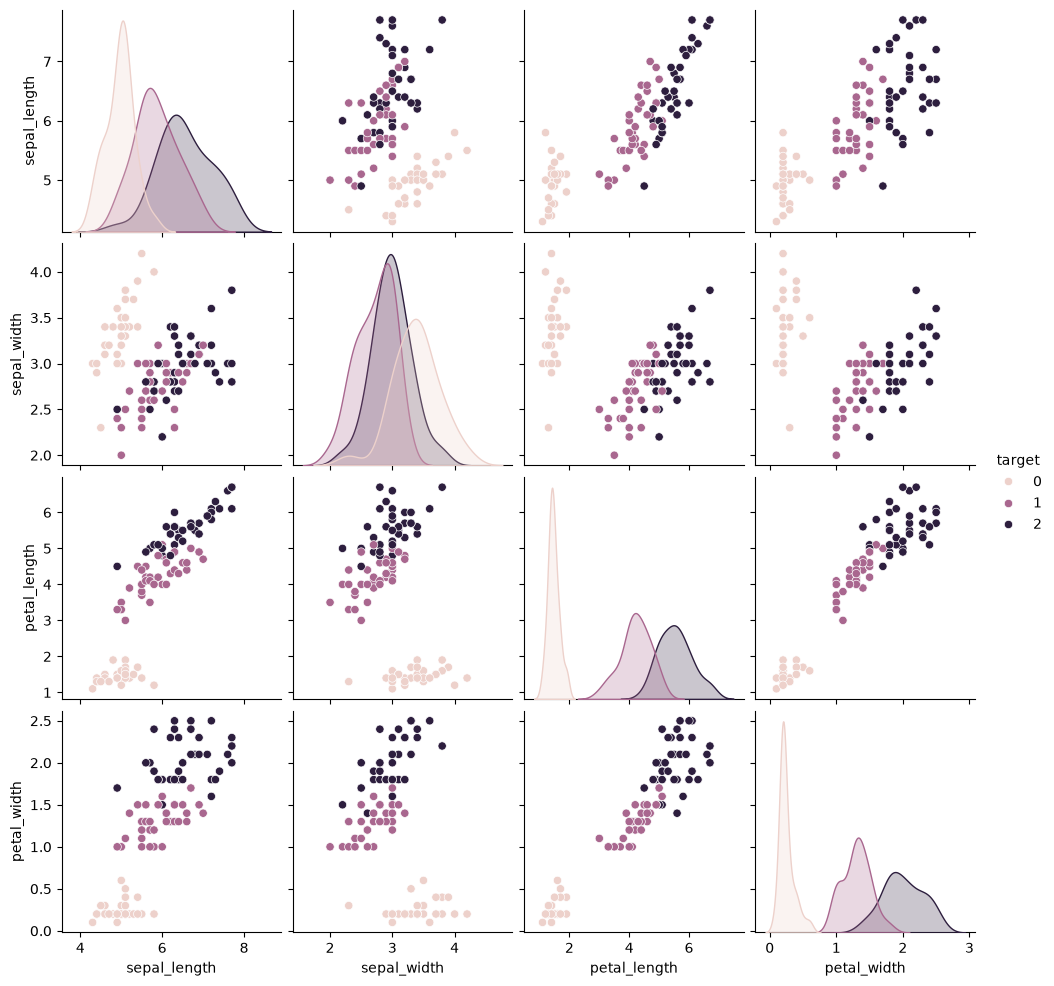

In [37]:
import seaborn as sns

plot = sns.pairplot(train_df, hue="target")
plot.savefig("./plots/pairplot.png")

# 2. Training and model selection

In [52]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import KFold, GridSearchCV

param_grid = {
    "estimator__kernel": ["linear", "poly", "rbf", ]
}

svc = CalibratedClassifierCV(SVC(), ensemble=False)
kfold = KFold(n_splits=3, shuffle=True, random_state=67)

grid_search = GridSearchCV(
    estimator=svc,
    param_grid=param_grid,
    scoring="neg_log_loss",
    refit=True,
    cv=kfold
)

grid_search.fit(X_train, y_train)
y_hat = grid_search.predict(X_train)

grid_search.best_estimator_

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",SVC(kernel='poly')
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",False
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,[<sklearn.cali...0020385BAF230>]
"classes_ clas

In [40]:
from sklearn.metrics import confusion_matrix, accuracy_score

print(f"Accuracy score: {accuracy_score(y_train, y_hat)}")
confusion_matrix(y_true=y_train, y_pred=y_hat)

Accuracy score: 0.9809523809523809


array([[31,  0,  0],
       [ 0, 35,  2],
       [ 0,  0, 37]])

# 3. Prediction and submission

In [51]:
y_pred = grid_search.predict(X_test)

# Create a submission file
submission = pd.DataFrame({'id': X_test.index, 'target': y_pred})
submission.to_csv('./data/submission.csv', index=False)